In [1]:
import numpy as np 
import pandas as pd 
import anndata as ad 
import scanpy as sc 
import matplotlib.pyplot as plt 

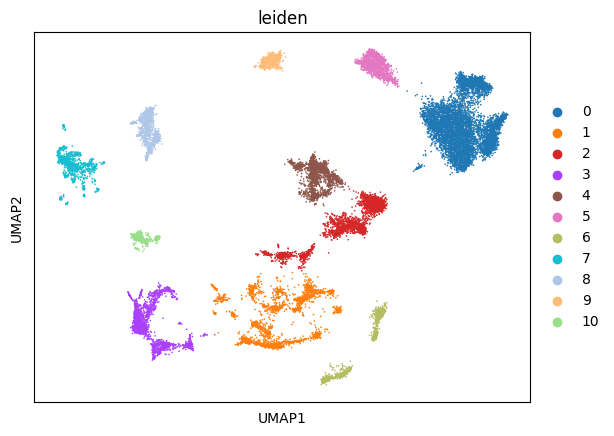

In [2]:
## load raw data

scdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data/sly_05_require/multi_modify.h5ad')
sc.pl.umap(scdata, color = 'leiden')

In [3]:
## load rna data 
rna = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data/new_rna/ex_neuron.h5ad')

mutual_gene = np.intersect1d(rna.var.index, scdata.var.index)
print(mutual_gene.shape) 

sc_var = scdata.var.copy()
scdata.var = sc_var 
scdata = scdata[:,mutual_gene] 

rna = rna[:,mutual_gene]
print(rna.shape, scdata.shape)

(9911,)
(27320, 9911) (21723, 9911)


## 训练分类器分类

分类报告：
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       653
           1       0.95      0.96      0.95       287
          10       0.97      0.92      0.94        64
           2       0.94      0.92      0.93       264
           3       0.98      0.96      0.97       169
           4       0.95      0.91      0.93       184
           5       0.98      0.98      0.98       146
           6       0.95      0.95      0.95       105
           7       0.96      0.95      0.96       137
           8       0.96      0.96      0.96       115
           9       0.85      0.96      0.90        49

    accuracy                           0.96      2173
   macro avg       0.95      0.95      0.95      2173
weighted avg       0.96      0.96      0.96      2173

混淆矩阵：


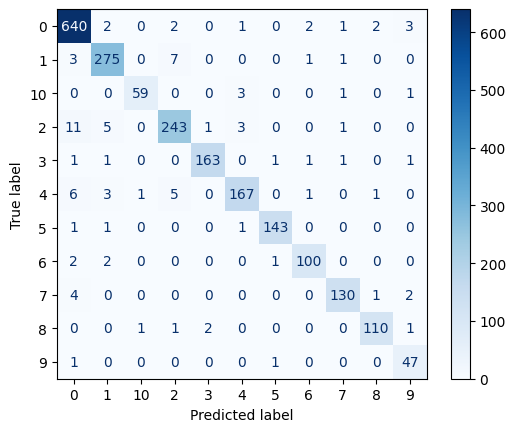

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression



X = scdata.X.toarray() 
y = scdata.obs.leiden.astype(str)


# 将字符串标签编码为整数
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)  # 编码后的标签

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.1, random_state=42
)

# 训练随机森林分类器
#rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
#rf_classifier.fit(X_train, y_train)
model = LogisticRegression() 
model.fit(X_train, y_train)

# 在测试集上进行预测
y_pred = model.predict(X_test)

# 将预测结果解码回原始字符串标签
y_test_decoded = label_encoder.inverse_transform(y_test)  # 真实标签
y_pred_decoded = label_encoder.inverse_transform(y_pred)  # 预测标签

# 打印分类报告
print("分类报告：")
print(classification_report(y_test_decoded, y_pred_decoded))

# 打印混淆矩阵
print("混淆矩阵：")
cm = confusion_matrix(y_test_decoded, y_pred_decoded, labels=label_encoder.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap="Blues")
plt.show()


In [5]:
sc.pp.normalize_total(rna, target_sum=1e4)
sc.pp.log1p(rna) 

pred_X = rna.X.toarray() 

#pred_prob = rf_classifier.predict_proba(pred_X)
#print(pred_prob.shape) 

pred_label = model.predict(pred_X)#np.argmax(pred_prob, axis=1) 
pred_label = label_encoder.inverse_transform(pred_label) 

/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


In [ ]:
sc.pp.neighbors(rna, use_rep = 'X_pca_harmony', n_neighbors = 30)

sc.tl.umap(rna, min_dist = 0.5)
sc.tl.leiden(rna, resolution = 0.1)
sc.pl.umap(rna, color = ['leiden'])

rna.obs.loc[:,'ref_label'] = pred_label 

sc.tl.leiden(rna, resolution = 0.6)
sc.pl.umap(rna, color = ['ref_label', 'leiden'])


In [ ]:
ref_dic = {'0': '0',
           '1': '8',
           '2': '3',
           '3': '0',
           '4': '1',
           '5': '10',
           '6': '10',
           '7': '2',
           '8': '8',
    }
rna.obs.loc[:,'ref_leiden'] = rna.obs.leiden.map(ref_dic)
sc.pl.umap(rna, color = ['ref_leiden'],save = 'scrna_label.pdf')

In [8]:
rna.write('rna_label.h5ad')